# CloudShield · Classification Track (Part A + Part B) · TON_IoT

**23CSE301 Machine Learning · Capstone · Review 2**

**Question:** given one network flow, which kind of traffic is it? Normal, or one of nine attack types.

**Dataset:** TON_IoT, network portion (`train_test_network.csv`), UNSW Canberra. 211,043 flows, 44 columns, 10 classes.

| Rubric item | Where |
|---|---|
| Part A: Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC | Section 4 |
| Part B: Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP | Section 5 |
| Accuracy, Precision, Recall, weighted F1, confusion matrix, ROC-AUC (OvR) for every model | Sections 4 to 6 |
| One table comparing all 10 algorithms | Section 6 |
| 5-fold CV of the two best models | Section 7 |
| Hyperparameter tuning of every model (summary table at the end of Section 6) | Sections 4 to 6 |
| Final model: wider GridSearchCV, before/after | Section 8 |

**How to run on Kaggle:** *Add Input* → attach a TON_IoT dataset that contains `train_test_network.csv` → *Run All*. CPU is enough; about 50 minutes (the final GridSearchCV in Section 8 is close to half). All outputs (tables, figures, the final model) are written to `/kaggle/working`.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
SVC_SAMPLE = 20_000   # RBF SVC is O(n^2) in memory and time; trained on a stratified subsample (documented below)

## 1. Load and audit the data

In [2]:
import glob, os

def find_data(name="train_test_network.csv"):
    """Kaggle: any attached dataset that contains the file. Locally: the repo's data/raw folder."""
    patterns = [f"/kaggle/input/**/{name}", f"/kaggle/input/**/{name.title()}", f"/kaggle/input/**/Train_Test_Network.csv",
                f"../data/raw/TON_IoT/{name}", f"data/raw/TON_IoT/{name}", f"../data/raw/toniot/{name}", f"data/raw/toniot/{name}"]
    for p in patterns:
        hits = glob.glob(p, recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(
        "train_test_network.csv not found. On Kaggle: Add Input -> search 'TON_IoT train_test_network' and attach it. "
        "Locally: put the file in data/raw/TON_IoT/.")

DATA_PATH = find_data()
ON_KAGGLE = DATA_PATH.startswith("/kaggle/")
OUT_DIR = "/kaggle/working" if ON_KAGGLE else "../results"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("data:", DATA_PATH)
print("outputs:", OUT_DIR)

data: ../data/raw/TON_IoT/train_test_network.csv
outputs: ../results


In [3]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("shape:", raw.shape)
print("\ndtypes:", raw.dtypes.value_counts().to_dict())
print("\nmissing values (NaN):", int(raw.isna().sum().sum()))
dash = (raw.astype(str) == "-").sum()
print("\n'-' placeholders (Zeek's marker for 'not applicable'), top columns:")
print(dash[dash > 0].sort_values(ascending=False).head(12).to_string())

shape: (211043, 44)

dtypes: {dtype('O'): 27, dtype('int64'): 16, dtype('float64'): 1}



missing values (NaN): 0



'-' placeholders (Zeek's marker for 'not applicable'), top columns:
ssl_subject             211032
ssl_issuer              211032
http_orig_mime_types    211027
weird_addl              210886
http_resp_mime_types    210839
http_uri                210756
http_method             210756
http_user_agent         210756
http_version            210745
http_trans_depth        210740
weird_name              210687
weird_notice            210687


exact duplicate rows: 20,569 (9.7%)


after dropping duplicates: (190474, 44)


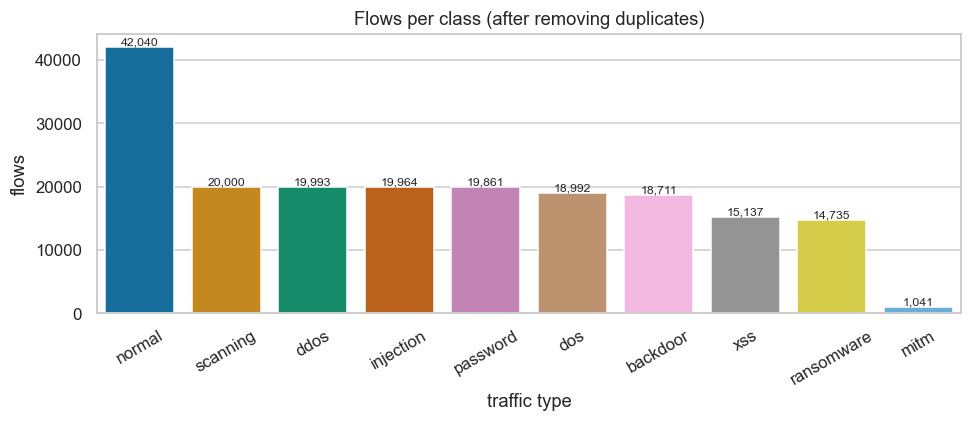

type
normal        42040
scanning      20000
ddos          19993
injection     19964
password      19861
dos           18992
backdoor      18711
xss           15137
ransomware    14735
mitm           1041


In [4]:
dups = raw.duplicated().sum()
print(f"exact duplicate rows: {dups:,} ({dups / len(raw):.1%})")
df = raw.drop_duplicates(ignore_index=True)
print("after dropping duplicates:", df.shape)

counts = df["type"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="colorblind")
ax.set_title("Flows per class (after removing duplicates)")
ax.set_xlabel("traffic type"); ax.set_ylabel("flows")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "cls_01_class_distribution.png"), bbox_inches="tight"); plt.show()
print(counts.to_string())

> **Observation (write in your own words):** How balanced are the classes? Which class is rare, and what does that mean for accuracy as a metric?
>
> _…_

## 2. Features

**Removed before modelling**

- `src_ip`, `dst_ip`, `src_port`: they identify machines. In this testbed each attack type comes from only 2 to 6 source machines, so a model that sees IPs can learn *who* attacked instead of *what the traffic looks like*.
- Free-text fields (`dns_query`, `http_uri`, `http_user_agent`, `ssl_subject`, …): hundreds of unique strings, almost all `-`.
- `label`: it is 0 exactly when `type` is `normal`, so keeping it would leak the answer.

**Engineered** (justification in the code comments)

- `log1p` of byte, packet and duration counts, which span several orders of magnitude.
- `bytes_per_src_pkt`, `bytes_per_dst_pkt`: average packet size each way. Floods and scans send many small, uniform packets.
- `has_reply`: whether the destination answered at all. Port scans often get no reply.
- `dst_port_bucket`: the ten most common destination ports keep their number, the rest become `other`. The ten are chosen from the training rows only.

The preprocessing builds on the feature choices in `03_classification_1.ipynb` (log transform, `-` handling, top-10 port bucket).

In [5]:
# Columns that identify a machine or hold free text. A model that sees them can memorise
# which testbed host ran which attack instead of learning what the traffic looks like.
IDENTIFIERS = ["src_ip", "dst_ip", "src_port"]
FREE_TEXT = ["dns_query", "ssl_subject", "ssl_issuer", "http_uri", "http_user_agent", "http_orig_mime_types",
             "http_resp_mime_types", "http_trans_depth", "http_version", "weird_addl"]
# `label` is 0 exactly when `type` is normal, so it is the answer in disguise.
TARGET, LEAKY_TARGET = "type", "label"

# Heavy-tailed counts: log1p squeezes values that span several orders of magnitude.
LOG_COLS = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "dst_pkts", "src_ip_bytes",
            "dst_ip_bytes", "http_request_body_len", "http_response_body_len"]
# Low-cardinality codes and flags, one-hot encoded. Numeric codes such as dns_qtype are labels, not quantities.
CAT_COLS = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected", "ssl_version",
            "ssl_cipher", "ssl_resumed", "ssl_established", "http_method", "weird_name", "weird_notice",
            "dns_qtype", "dns_rcode", "dns_qclass", "http_status_code", "dst_port_bucket"]


def build_features(d, top_ports):
    """Engineered feature table. `top_ports` must come from the training rows only."""
    X = pd.DataFrame(index=d.index)
    for c in LOG_COLS:
        X[c] = np.log1p(d[c].clip(lower=0))
    # engineered: average packet size each way (scans and floods send tiny, uniform packets)
    X["bytes_per_src_pkt"] = np.log1p(d["src_bytes"] / d["src_pkts"].replace(0, np.nan)).fillna(0)
    X["bytes_per_dst_pkt"] = np.log1p(d["dst_bytes"] / d["dst_pkts"].replace(0, np.nan)).fillna(0)
    # engineered: did the other side answer at all? (S0/REJ scans often get no reply)
    X["has_reply"] = (d["dst_pkts"] > 0).astype(int)
    # engineered: the ten most common destination ports keep their number, the rest become "other"
    port = d["dst_port"].where(d["dst_port"].isin(top_ports))
    X["dst_port_bucket"] = port.map(lambda p: "other" if pd.isna(p) else str(int(p)))
    for c in CAT_COLS:
        if c != "dst_port_bucket":
            X[c] = d[c].astype(str)
    return X

## 3. Train/test split, encoding and scaling

One **stratified 80:20 split** (`random_state=42`) shared by all ten models, so every model is scored on exactly the same flows. Every transform below (top ports, one-hot categories, scaler) is fitted on the training rows only.

*Why not split by source machine?* We tried it (`StratifiedGroupKFold` on `src_ip`): because each attack comes from so few machines, a test fold holds only some of the classes (8 of the 10 in Section 9), which makes a 10-class comparison table, confusion matrix and ROC-AUC impossible. Section 9 still runs that split on the final model as a stress test.

In [6]:
y_text = df[TARGET].values
le = LabelEncoder().fit(y_text)
y = le.transform(y_text)
CLASSES = list(le.classes_)

idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y, random_state=RANDOM_STATE)
train_raw, test_raw = df.iloc[idx_train], df.iloc[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

top_ports = train_raw["dst_port"].value_counts().head(10).index
F_train, F_test = build_features(train_raw, top_ports), build_features(test_raw, top_ports)

num_cols = [c for c in F_train.columns if pd.api.types.is_numeric_dtype(F_train[c])]
cat_cols = [c for c in F_train.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat_cols),
])
X_train = pre.fit_transform(F_train)          # fitted on the training rows only
X_test = pre.transform(F_test)
FEATURE_NAMES = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]

print(f"train {X_train.shape}, test {X_test.shape}")
print("test class counts:", dict(zip(CLASSES, np.bincount(y_test))))

train (152379, 107), test (38095, 107)
test class counts: {'backdoor': np.int64(3742), 'ddos': np.int64(3999), 'dos': np.int64(3799), 'injection': np.int64(3993), 'mitm': np.int64(208), 'normal': np.int64(8408), 'password': np.int64(3972), 'ransomware': np.int64(2947), 'scanning': np.int64(4000), 'xss': np.int64(3027)}


In [7]:
RESULTS, PRED, PROBA = {}, {}, {}

def evaluate(name, model, X_tr=None, y_tr=None, note=""):
    """Fit on the training split (or a given subset), score on the shared test split."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    t0 = time.time(); model.fit(X_tr, y_tr); fit_s = time.time() - t0
    t0 = time.time()
    proba = model.predict_proba(X_test)
    pred = model.classes_[proba.argmax(1)]
    pred_s = time.time() - t0
    RESULTS[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (w)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (w)": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 (w)": f1_score(y_test, pred, average="weighted", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=model.classes_),
        "Fit (s)": fit_s, "Predict (s)": pred_s, "Train rows": len(y_tr), "Note": note,
    }
    PRED[name], PROBA[name] = pred, proba
    print(f"{name}: " + ", ".join(f"{k} {v:.4f}" for k, v in RESULTS[name].items() if isinstance(v, float) and "(s)" not in k)
          + f"  [fit {fit_s:.1f}s]")
    return model


def show_cm(name):
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_test, PRED[name], normalize="true"), display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name}: normalised confusion matrix (test set)")
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

MODELS, TUNED = {}, []
# Hyperparameters are searched with 3-fold CV on a fixed 20,000-row stratified sample of the TRAINING set
# (searching on all 152k rows for ten models would take hours); the chosen settings are then trained on the full training set.
sub, _ = train_test_split(np.arange(len(y_train)), train_size=20_000, stratify=y_train, random_state=RANDOM_STATE)

def tune(name, estimator, grid, rows=None):
    rows = sub if rows is None else rows
    t0 = time.time()
    gs = GridSearchCV(estimator, grid, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="f1_weighted", n_jobs=-1)
    gs.fit(X_train[rows], y_train[rows])
    TUNED.append({"Model": name, "searched": str(grid), "best": str(gs.best_params_), "CV F1 (w)": gs.best_score_,
                  "configs tried": len(gs.cv_results_["params"]), "time (s)": time.time() - t0})
    print(f"{name}: best {gs.best_params_}  CV F1 {gs.best_score_:.4f}  ({len(gs.cv_results_['params'])} configs)")
    return gs.best_params_

## 4. Part A: five baseline classifiers

### 4.1 Logistic Regression
Baseline linear model. `class_weight='balanced'` so the rare `mitm` class is not ignored; regularisation strength `C` tuned by 3-fold CV.

Logistic Regression: best {'C': 10}  CV F1 0.9438  (3 configs)


Logistic Regression: Accuracy 0.9536, Precision (w) 0.9674, Recall (w) 0.9536, F1 (w) 0.9590, F1 (macro) 0.8996, ROC-AUC (OvR) 0.9960  [fit 83.7s]


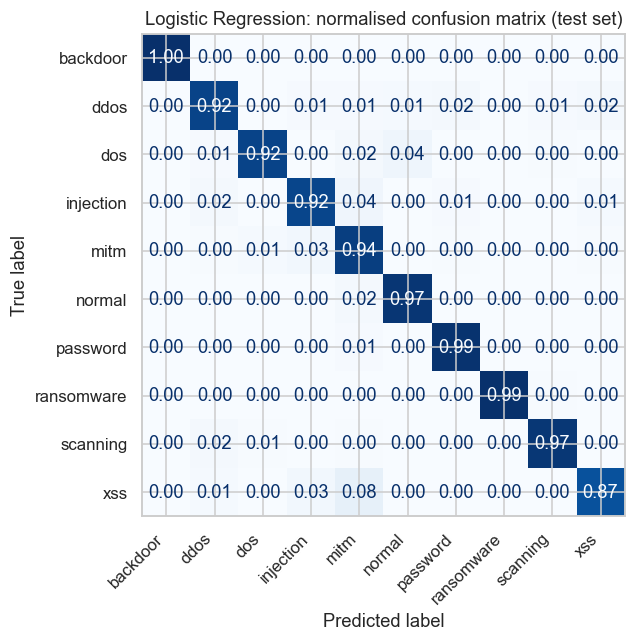

In [8]:
bp = tune("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE), {"C": [0.1, 1, 10]})
MODELS["Logistic Regression"] = evaluate("Logistic Regression",
    LogisticRegression(**bp, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE), note=f"class_weight=balanced, {bp}")
show_cm("Logistic Regression")

In [9]:
# Interpreting the coefficients: features that most raise the odds of three attack classes
lr = MODELS["Logistic Regression"]
rows = []
for cls_name in ["ddos", "scanning", "password"]:
    k = CLASSES.index(cls_name)
    top = np.argsort(-lr.coef_[k])[:5]
    rows += [{"class": cls_name, "feature": FEATURE_NAMES[j], "coefficient": lr.coef_[k, j], "odds x": np.exp(lr.coef_[k, j])} for j in top]
pd.DataFrame(rows).round(3)

,class,feature,coefficient,odds x
0,ddos,conn_state_SHR,11.953,1.553592e+05
1,ddos,conn_state_OTH,10.440,3.420646e+04
2,ddos,service_-,10.017,2.240380e+04
3,ddos,conn_state_S3,7.442,1.706124e+03
4,ddos,dns_RA_F,6.807,9.043770e+02
5,scanning,dns_rejected_T,17.895,5.912660e+07
6,scanning,src_bytes,15.424,4.993120e+06
7,scanning,src_ip_bytes,13.525,7.475196e+05
8,scanning,dns_RA_T,13.112,4.947239e+05
9,scanning,conn_state_S0,10.428,3.379559e+04


> **Observation (write in your own words):** Do the strongest coefficients make sense for each attack (for example packet size for DDoS, `has_reply` for scanning)?
>
> _…_

### 4.2 K-Nearest Neighbors
`k`, the vote weighting and the distance metric (`p=1` Manhattan, `p=2` Euclidean) are chosen by 3-fold CV on the tuning sample. Features are scaled first; unscaled byte counts would dominate any distance.

K-Nearest Neighbors: best {'n_neighbors': 5, 'p': 1, 'weights': 'distance'}  CV F1 0.9783  (16 configs)


K-Nearest Neighbors: Accuracy 0.9864, Precision (w) 0.9865, Recall (w) 0.9864, F1 (w) 0.9865, F1 (macro) 0.9637, ROC-AUC (OvR) 0.9935  [fit 0.1s]


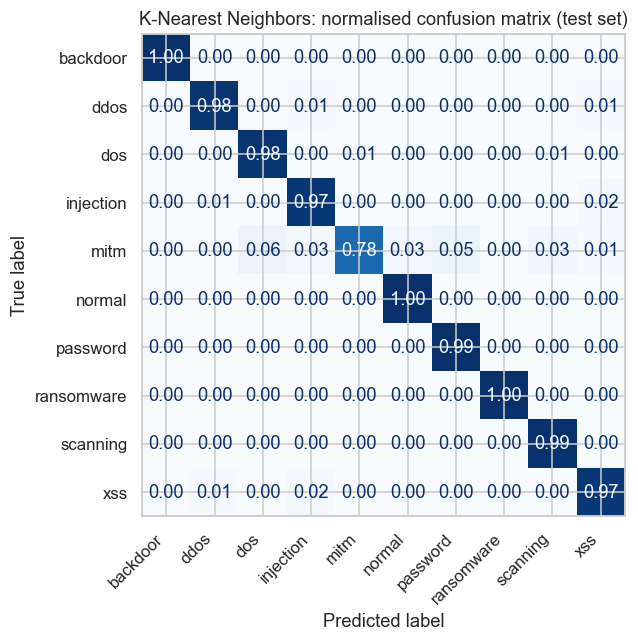

In [10]:
bp = tune("K-Nearest Neighbors", KNeighborsClassifier(n_jobs=-1), {"n_neighbors": [3, 5, 9, 15], "weights": ["uniform", "distance"], "p": [1, 2]})
MODELS["K-Nearest Neighbors"] = evaluate("K-Nearest Neighbors", KNeighborsClassifier(**bp, n_jobs=-1), note=str(bp))
show_cm("K-Nearest Neighbors")

### 4.3 Gaussian Naive Bayes
Assumes every feature is independent of the others given the class. Byte counts, packet counts and their ratios are strongly correlated, so this assumption is violated by design.

Gaussian NB: Accuracy 0.4455, Precision (w) 0.5749, Recall (w) 0.4455, F1 (w) 0.4361, F1 (macro) 0.4245, ROC-AUC (OvR) 0.9467  [fit 0.5s]


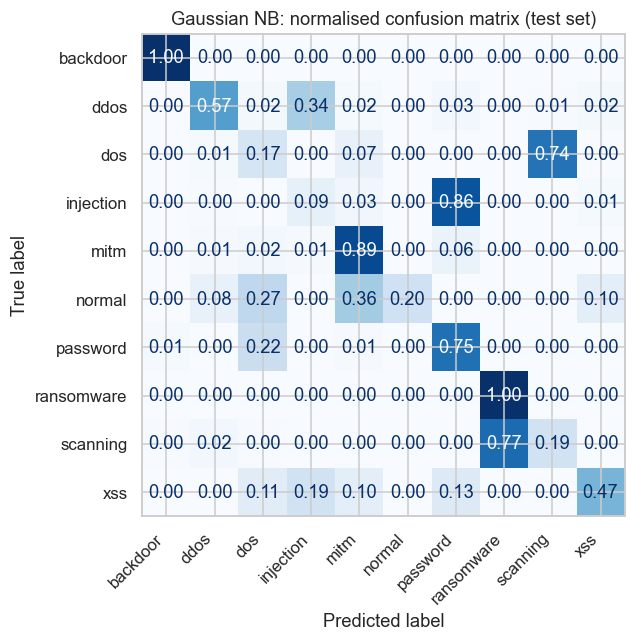

In [11]:
MODELS["Gaussian NB"] = evaluate("Gaussian NB", GaussianNB(), note="independence assumption violated")
show_cm("Gaussian NB")

### 4.4 Decision Tree
`max_depth` and `min_samples_leaf` chosen by 3-fold CV on the full training set.

Decision Tree: best {'max_depth': 25, 'min_samples_leaf': 1}  CV F1 0.9848  (8 configs)


Decision Tree: Accuracy 0.9854, Precision (w) 0.9865, Recall (w) 0.9854, F1 (w) 0.9858, F1 (macro) 0.9566, ROC-AUC (OvR) 0.9891  [fit 7.7s]


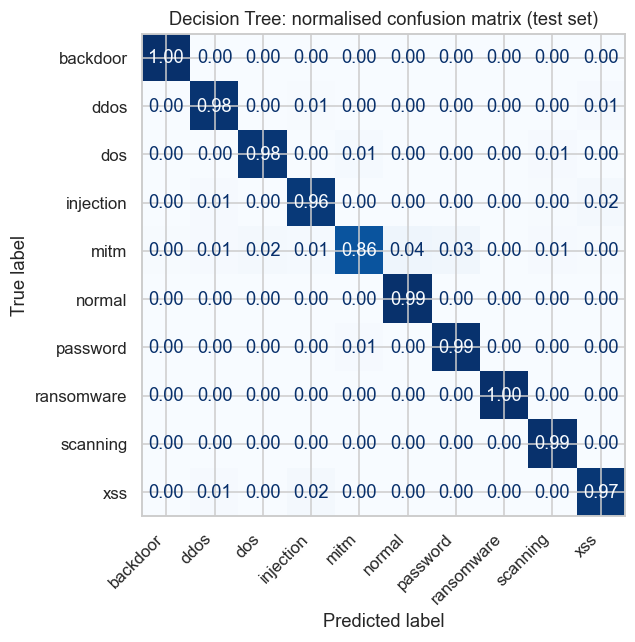

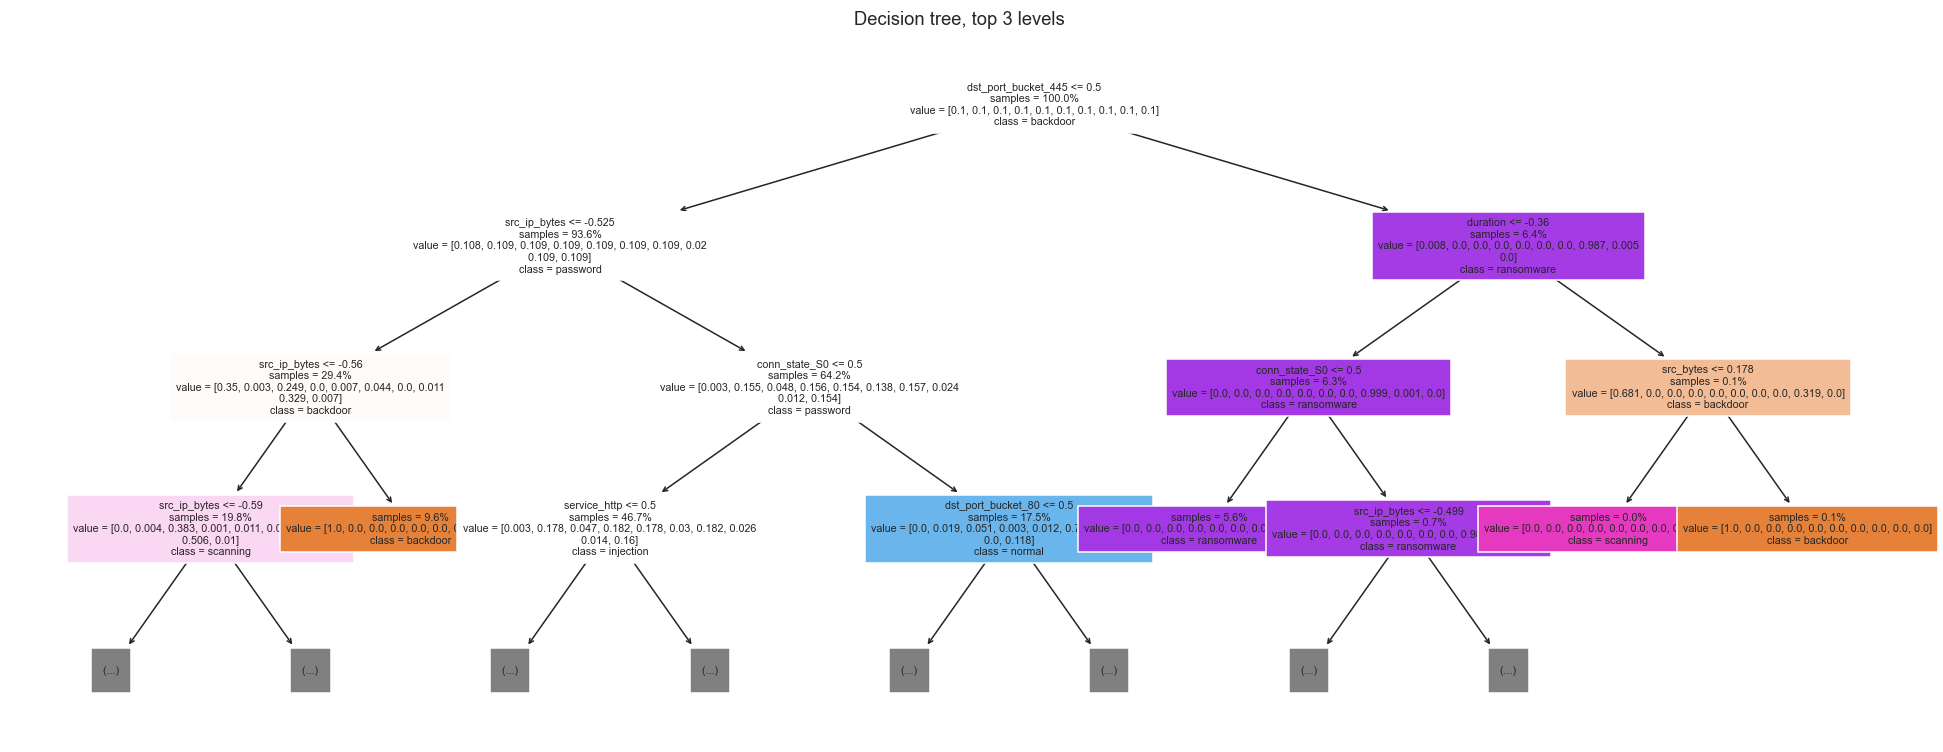

In [12]:
# a single tree is cheap, so its settings are searched on the full training set
bp = tune("Decision Tree", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
          {"max_depth": [8, 15, 25, None], "min_samples_leaf": [1, 3]}, rows=np.arange(len(y_train)))
MODELS["Decision Tree"] = evaluate("Decision Tree", DecisionTreeClassifier(**bp, class_weight="balanced", random_state=RANDOM_STATE), note=str(bp))
show_cm("Decision Tree")

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(MODELS["Decision Tree"], max_depth=3, feature_names=FEATURE_NAMES, class_names=CLASSES, filled=True,
          fontsize=7, impurity=False, proportion=True, ax=ax)
ax.set_title("Decision tree, top 3 levels")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cls_02_decision_tree.png"), bbox_inches="tight"); plt.show()

### 4.5 Support Vector Machine
Kernel SVMs scale quadratically with the number of rows, so the SVC is trained on a **20,000-row stratified sample** of the training set and scored on the same full test set as every other model. The kernel (RBF, polynomial, linear), `C` and the kernel parameters are tuned by 3-fold CV on a smaller 6,000-row sample.

SVC: best {'C': 50, 'gamma': 0.05, 'kernel': 'rbf'}  CV F1 0.9560  (9 configs)


SVC: Accuracy 0.9767, Precision (w) 0.9772, Recall (w) 0.9767, F1 (w) 0.9768, F1 (macro) 0.9426, ROC-AUC (OvR) 0.9970  [fit 40.3s]


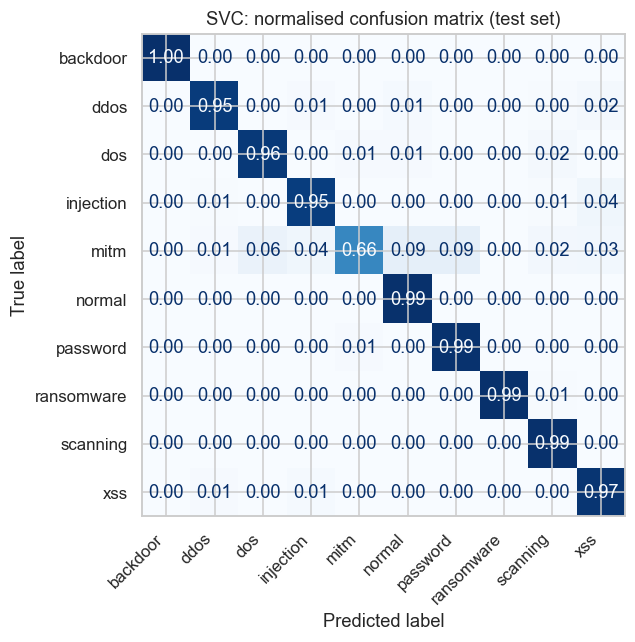

In [13]:
svc_idx, _ = train_test_split(np.arange(len(y_train)), train_size=SVC_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)
tune_idx = svc_idx[:6000]
# max_iter caps the libsvm solver: polynomial and linear kernels can otherwise run for a very long time on this data
bp = tune("SVC", SVC(max_iter=100_000, cache_size=1000, random_state=RANDOM_STATE),
          [{"kernel": ["rbf"], "C": [1, 10, 50], "gamma": ["scale", 0.05]},
           {"kernel": ["poly"], "C": [1, 10], "degree": [2]},
           {"kernel": ["linear"], "C": [1]}], rows=tune_idx)
MODELS["SVC"] = evaluate("SVC", SVC(probability=True, max_iter=200_000, cache_size=1000, random_state=RANDOM_STATE, **bp),
                         X_tr=X_train[svc_idx], y_tr=y_train[svc_idx], note=f"{bp}; trained on {SVC_SAMPLE:,}-row sample")
show_cm("SVC")

> **Observation (write in your own words):** Which Part A model is strongest, which is weakest, and why does Gaussian NB behave the way it does?
>
> _…_

## 5. Part B: five ensemble and neural models

### 5.1 Random Forest
Bagged decision trees with a random subset of features at each split. `n_estimators` and `max_features` tuned by 3-fold CV.

Random Forest: best {'max_features': 0.3, 'n_estimators': 100}  CV F1 0.9798  (6 configs)


Random Forest: Accuracy 0.9864, Precision (w) 0.9865, Recall (w) 0.9864, F1 (w) 0.9864, F1 (macro) 0.9645, ROC-AUC (OvR) 0.9979  [fit 8.1s]


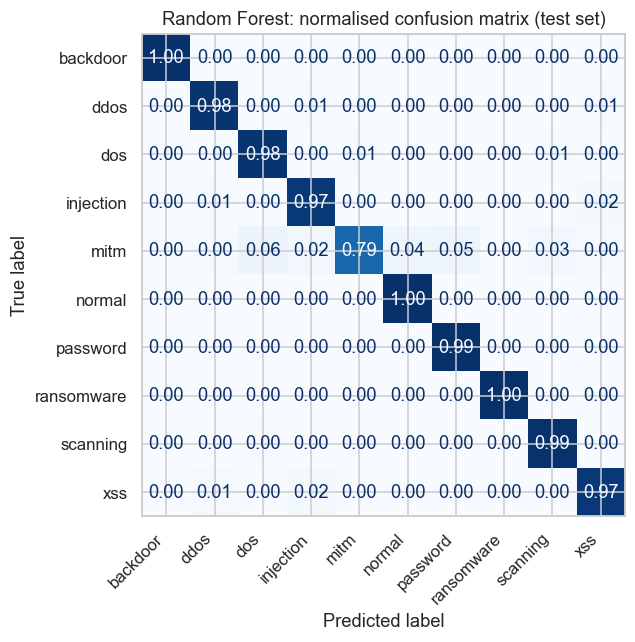

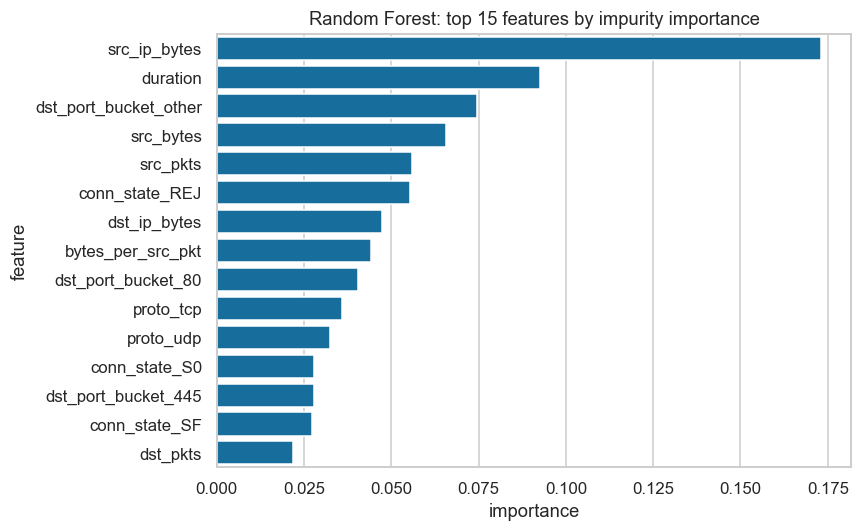

In [14]:
bp = tune("Random Forest", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
          {"n_estimators": [100, 200, 400], "max_features": ["sqrt", 0.3]})
MODELS["Random Forest"] = evaluate("Random Forest", RandomForestClassifier(**bp, n_jobs=-1, random_state=RANDOM_STATE), note=str(bp))
show_cm("Random Forest")

imp = pd.Series(MODELS["Random Forest"].feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, ax=ax, color=sns.color_palette("colorblind")[0])
ax.set_title("Random Forest: top 15 features by impurity importance"); ax.set_xlabel("importance"); ax.set_ylabel("feature")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cls_03_rf_importance.png"), bbox_inches="tight"); plt.show()

### 5.2 AdaBoost
The default one-split stump is too weak for ten classes; a depth-3 tree is used as the weak learner (as found in `03_classification_1.ipynb`). `n_estimators` and `learning_rate` tuned by 3-fold CV.

AdaBoost: best {'learning_rate': 0.5, 'n_estimators': 300}  CV F1 0.9530  (9 configs)


AdaBoost: Accuracy 0.9093, Precision (w) 0.9162, Recall (w) 0.9093, F1 (w) 0.9092, F1 (macro) 0.8583, ROC-AUC (OvR) 0.9650  [fit 1027.1s]


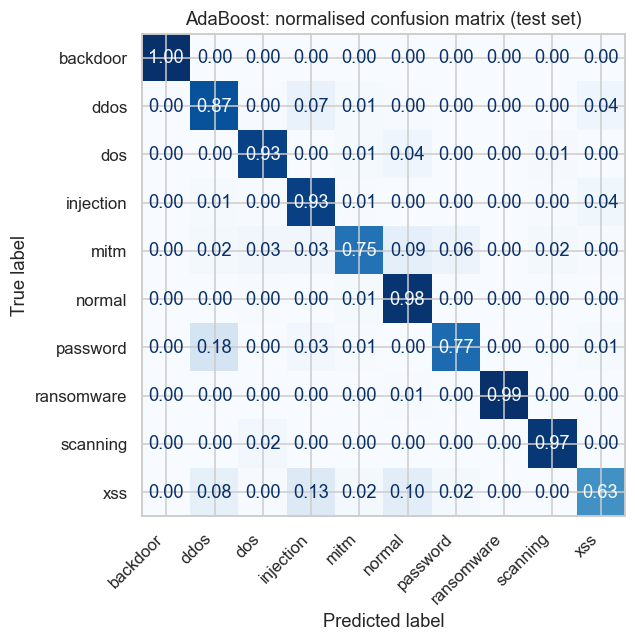

In [15]:
ada = lambda **kw: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), random_state=RANDOM_STATE, **kw)
bp = tune("AdaBoost", ada(), {"n_estimators": [50, 150, 300], "learning_rate": [0.1, 0.5, 1.0]})
MODELS["AdaBoost"] = evaluate("AdaBoost", ada(**bp), note=f"depth-3 trees, {bp}")
show_cm("AdaBoost")

### 5.3 Gradient Boosting
scikit-learn's histogram gradient boosting (`HistGradientBoostingClassifier`), the fast implementation of sklearn GBM for large datasets. `learning_rate` and the number of boosting rounds tuned by 3-fold CV.

Gradient Boosting: best {'learning_rate': 0.05, 'max_iter': 200}  CV F1 0.9791  (6 configs)


Gradient Boosting: Accuracy 0.9881, Precision (w) 0.9882, Recall (w) 0.9881, F1 (w) 0.9881, F1 (macro) 0.9663, ROC-AUC (OvR) 0.9997  [fit 39.5s]


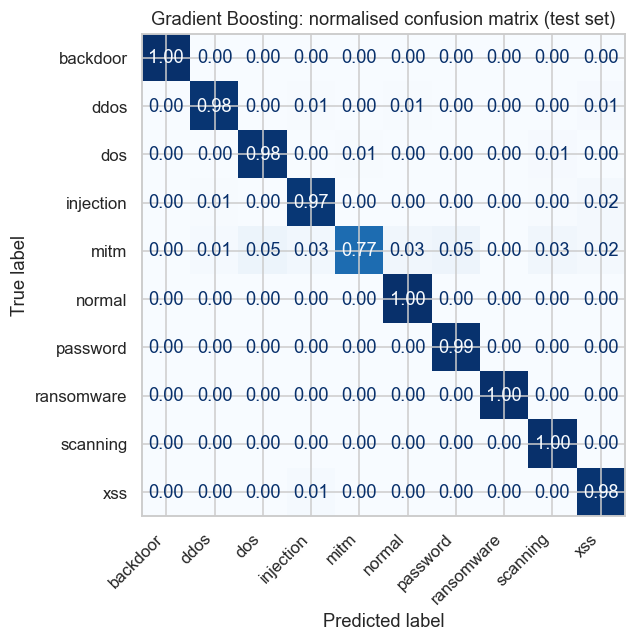

In [16]:
bp = tune("Gradient Boosting", HistGradientBoostingClassifier(random_state=RANDOM_STATE),
          {"learning_rate": [0.05, 0.1, 0.2], "max_iter": [200, 400]})
MODELS["Gradient Boosting"] = evaluate("Gradient Boosting", HistGradientBoostingClassifier(**bp, random_state=RANDOM_STATE), note=str(bp))
show_cm("Gradient Boosting")

### 5.4 Bagging
Full decision trees, each on a bootstrap sample of rows and a share of the features; `n_estimators` and `max_features` tuned by 3-fold CV.

Bagging: best {'max_features': 0.5, 'n_estimators': 100}  CV F1 0.9811  (4 configs)


Bagging: Accuracy 0.9870, Precision (w) 0.9872, Recall (w) 0.9870, F1 (w) 0.9871, F1 (macro) 0.9657, ROC-AUC (OvR) 0.9996  [fit 7.6s]


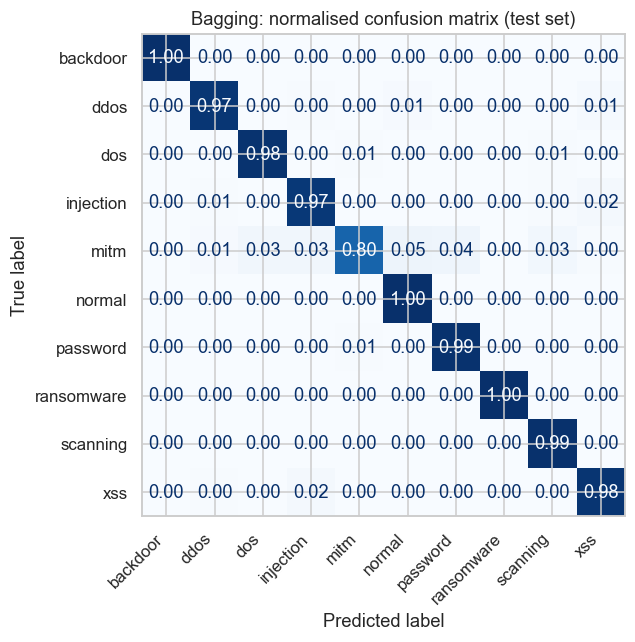

In [17]:
bag = lambda **kw: BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_jobs=-1, random_state=RANDOM_STATE, **kw)
bp = tune("Bagging", bag(), {"n_estimators": [50, 100], "max_features": [0.5, 0.8]})
MODELS["Bagging"] = evaluate("Bagging", bag(**bp), note=f"decision-tree base, {bp}")
show_cm("Bagging")

### 5.5 MLP (neural network)
Two hidden layers, ReLU, Adam, early stopping on a 10% validation slice. Labels are integer-encoded, which also avoids the `early_stopping` crash seen in `03_classification_1.ipynb`. `hidden_layer_sizes` and `activation` are tuned by 3-fold CV on the tuning sample.

MLP: best {'activation': 'tanh', 'hidden_layer_sizes': (128, 64)}  CV F1 0.9664  (4 configs)


MLP: Accuracy 0.9817, Precision (w) 0.9822, Recall (w) 0.9817, F1 (w) 0.9818, F1 (macro) 0.9537, ROC-AUC (OvR) 0.9995  [fit 291.5s]


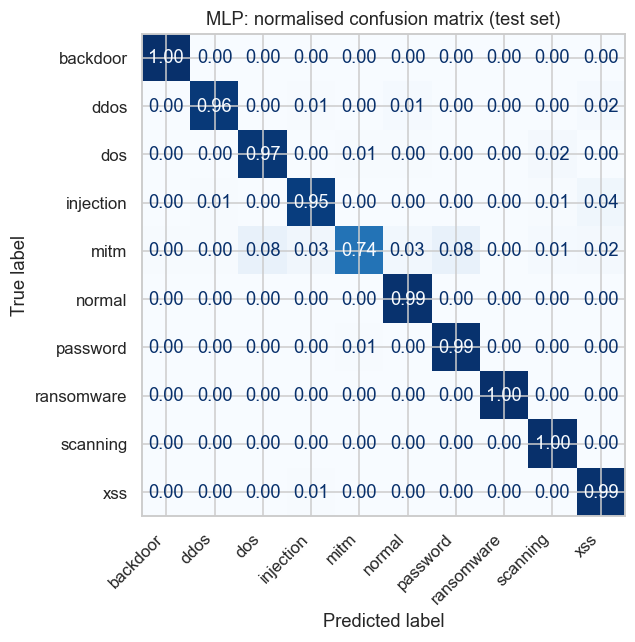

In [18]:
bp = tune("MLP", MLPClassifier(max_iter=200, early_stopping=True, random_state=RANDOM_STATE),
          {"hidden_layer_sizes": [(64,), (128, 64)], "activation": ["relu", "tanh"]})
MODELS["MLP"] = evaluate("MLP", MLPClassifier(**bp, max_iter=300, early_stopping=True, random_state=RANDOM_STATE), note=str(bp))
show_cm("MLP")

> **Observation (write in your own words):** How do the ensembles compare with the single Decision Tree? Is the neural network worth its training time here?
>
> _…_

## 6. All ten algorithms, one table

In [19]:
PART = {m: "A" for m in ["Logistic Regression", "K-Nearest Neighbors", "Gaussian NB", "Decision Tree", "SVC"]}
summary = (pd.DataFrame(RESULTS).T.assign(Part=lambda d: d.index.map(lambda m: PART.get(m, "B")))
           .sort_values("F1 (w)", ascending=False))
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.to_csv(os.path.join(OUT_DIR, "classification_results_ton_iot.csv"), index_label="Model")
metric_cols = ["Accuracy", "Precision (w)", "Recall (w)", "F1 (w)", "F1 (macro)", "ROC-AUC (OvR)"]
summary[["Rank", "Part"] + metric_cols + ["Fit (s)", "Train rows", "Note"]].style.format(
    {**{c: "{:.4f}" for c in metric_cols}, "Fit (s)": "{:.1f}", "Train rows": "{:,}"}).background_gradient(subset=["F1 (w)"], cmap="Greens")

,Rank,Part,Accuracy,Precision (w),Recall (w),F1 (w),F1 (macro),ROC-AUC (OvR),Fit (s),Train rows,Note
Gradient Boosting,1,B,0.9881,0.9882,0.9881,0.9881,0.9663,0.9997,39.5,"152,379","{'learning_rate': 0.05, 'max_iter': 200}"
Bagging,2,B,0.9870,0.9872,0.9870,0.9871,0.9657,0.9996,7.6,"152,379","decision-tree base, {'max_features': 0.5, 'n_estimators': 100}"
K-Nearest Neighbors,3,A,0.9864,0.9865,0.9864,0.9865,0.9637,0.9935,0.1,"152,379","{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}"
Random Forest,4,B,0.9864,0.9865,0.9864,0.9864,0.9645,0.9979,8.1,"152,379","{'max_features': 0.3, 'n_estimators': 100}"
Decision Tree,5,A,0.9854,0.9865,0.9854,0.9858,0.9566,0.9891,7.7,"152,379","{'max_depth': 25, 'min_samples_leaf': 1}"
MLP,6,B,0.9817,0.9822,0.9817,0.9818,0.9537,0.9995,291.5,"152,379","{'activation': 'tanh', 'hidden_layer_sizes': (128, 64)}"
SVC,7,A,0.9767,0.9772,0.9767,0.9768,0.9426,0.9970,40.3,"20,000","{'C': 50, 'gamma': 0.05, 'kernel': 'rbf'}; trained on 20,000-row sample"
Logistic Regression,8,A,0.9536,0.9674,0.9536,0.9590,0.8996,0.9960,83.7,"152,379","class_weight=balanced, {'C': 10}"
AdaBoost,9,B,0.9093,0.9162,0.9093,0.9092,0.8583,0.9650,1027.1,"152,379","depth-3 trees, {'learning_rate': 0.5, 'n_estimators': 300}"
Gaussian NB,10,A,0.4455,0.5749,0.4455,0.4361,0.4245,0.9467,0.5,"152,379",independence assumption violated


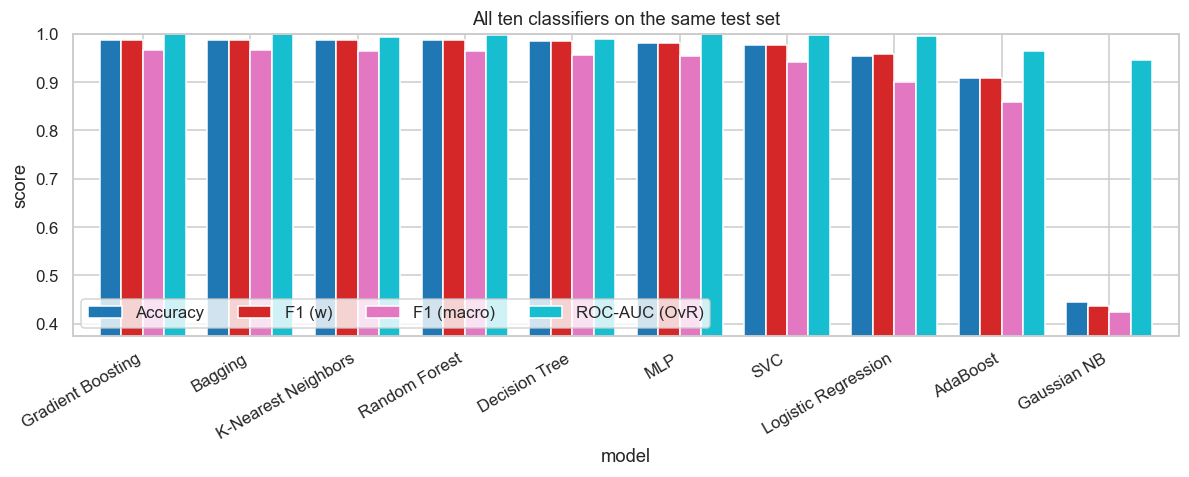

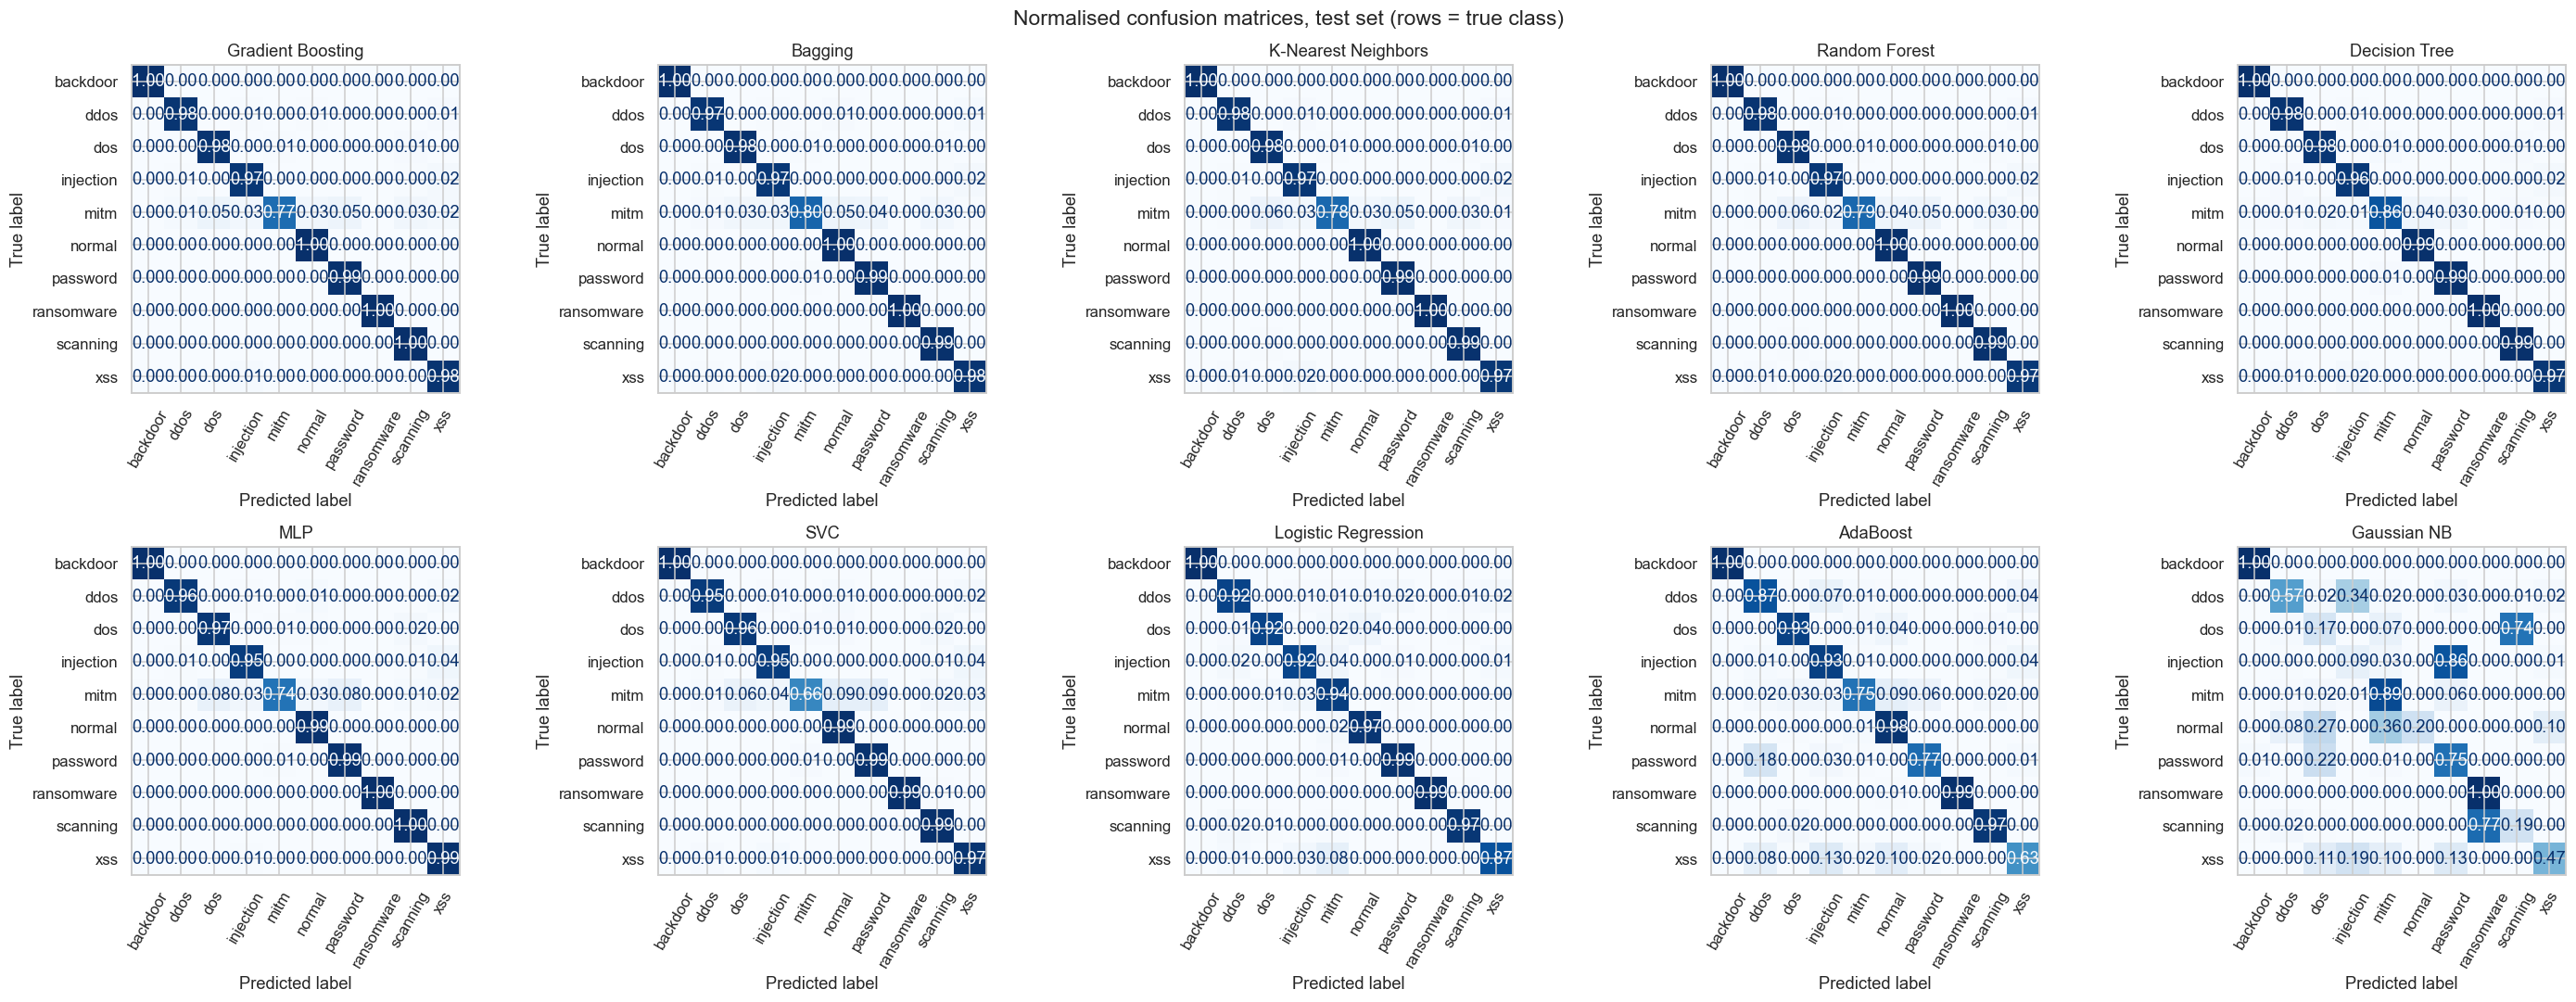

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.5))
summary[["Accuracy", "F1 (w)", "F1 (macro)", "ROC-AUC (OvR)"]].plot.bar(ax=ax, width=0.8, colormap="tab10")
ax.set_ylim(max(0, summary["F1 (macro)"].min() - 0.05), 1.0)
ax.set_title("All ten classifiers on the same test set"); ax.set_xlabel("model"); ax.set_ylabel("score")
ax.legend(loc="lower left", ncol=4); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "cls_04_model_comparison.png"), bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(2, 5, figsize=(26, 10))
for ax, name in zip(axes.ravel(), summary.index):
    ConfusionMatrixDisplay(confusion_matrix(y_test, PRED[name], normalize="true"), display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(name); ax.tick_params(axis="x", rotation=60)
plt.suptitle("Normalised confusion matrices, test set (rows = true class)", fontsize=15)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cls_05_confusion_matrices.png"), bbox_inches="tight"); plt.show()

> **Observation (write in your own words):** Which classes are confused with each other across most models? Does the ranking change between weighted F1 and macro F1?
>
> _…_

### Hyperparameters chosen for every model
Each model's settings were picked by 3-fold cross-validation on training data only; the test set was never used to choose them.

In [21]:
tuning_table = pd.DataFrame(TUNED).set_index("Model")
tuning_table.to_csv(os.path.join(OUT_DIR, "classification_tuning_ton_iot.csv"))
tuning_table.style.format({"CV F1 (w)": "{:.4f}", "time (s)": "{:.0f}"})

,searched,best,CV F1 (w),configs tried,time (s)
Model,,,,,
Logistic Regression,"{'C': [0.1, 1, 10]}",{'C': 10},0.9438,3,34
K-Nearest Neighbors,"{'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance'], 'p': [1, 2]}","{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}",0.9783,16,25
Decision Tree,"{'max_depth': [8, 15, 25, None], 'min_samples_leaf': [1, 3]}","{'max_depth': 25, 'min_samples_leaf': 1}",0.9848,8,17
SVC,"[{'kernel': ['rbf'], 'C': [1, 10, 50], 'gamma': ['scale', 0.05]}, {'kernel': ['poly'], 'C': [1, 10], 'degree': [2]}, {'kernel': ['linear'], 'C': [1]}]","{'C': 50, 'gamma': 0.05, 'kernel': 'rbf'}",0.9560,9,10
Random Forest,"{'n_estimators': [100, 200, 400], 'max_features': ['sqrt', 0.3]}","{'max_features': 0.3, 'n_estimators': 100}",0.9798,6,13
AdaBoost,"{'n_estimators': [50, 150, 300], 'learning_rate': [0.1, 0.5, 1.0]}","{'learning_rate': 0.5, 'n_estimators': 300}",0.9530,9,151
Gradient Boosting,"{'learning_rate': [0.05, 0.1, 0.2], 'max_iter': [200, 400]}","{'learning_rate': 0.05, 'max_iter': 200}",0.9791,6,40
Bagging,"{'n_estimators': [50, 100], 'max_features': [0.5, 0.8]}","{'max_features': 0.5, 'n_estimators': 100}",0.9811,4,9
MLP,"{'hidden_layer_sizes': [(64,), (128, 64)], 'activation': ['relu', 'tanh']}","{'activation': 'tanh', 'hidden_layer_sizes': (128, 64)}",0.9664,4,46


## 7. Cross-validation of the two best models
5-fold stratified CV on the training set only (the test set stays untouched).

In [22]:
top2 = list(summary.index[:2])
cv_rows = []
for name in top2:
    est = MODELS[name]
    Xcv, ycv = (X_train[svc_idx], y_train[svc_idx]) if name == "SVC" else (X_train, y_train)
    t0 = time.time()
    scores = cross_val_score(est, Xcv, ycv, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1_weighted", n_jobs=-1)
    cv_rows.append({"Model": name, "CV F1 (w) mean": scores.mean(), "std": scores.std(), "folds": np.round(scores, 4).tolist(),
                    "time (s)": time.time() - t0})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(os.path.join(OUT_DIR, "classification_cv_ton_iot.csv"), index=False)
cv_table

,Model,CV F1 (w) mean,std,folds,time (s)
0,Gradient Boosting,0.987198,0.000624,"[0.9884, 0.9868, 0.9872, 0.987, 0.9866]",210.995146
1,Bagging,0.986675,0.000797,"[0.9882, 0.986, 0.9864, 0.9867, 0.9861]",38.291837


## 8. Hyperparameter tuning of the best model
A wider GridSearchCV (3-fold, weighted F1) on the **full** training set. The table compares three versions of the same algorithm on the test set: library default settings, the settings tuned on the 20,000-row sample in Section 5, and this final search. The final model is the one chosen by cross-validation on training data; the test set is only used to report the result.

In [23]:
best_name = summary.index[0]
GRIDS = {
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
                      {"n_estimators": [200, 400], "min_samples_leaf": [1, 2], "max_features": ["sqrt", 0.3]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                          {"learning_rate": [0.05, 0.1], "max_iter": [300, 600], "max_leaf_nodes": [31, 63]}),
    "Bagging": (BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_jobs=-1, random_state=RANDOM_STATE),
                {"n_estimators": [100, 200], "max_features": [0.5, 0.8], "max_samples": [0.7, 1.0]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"max_depth": [15, 25, None], "min_samples_leaf": [1, 3, 5], "criterion": ["gini", "entropy"]}),
    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), random_state=RANDOM_STATE),
                 {"n_estimators": [150, 300], "learning_rate": [0.3, 0.5, 1.0]}),
    "K-Nearest Neighbors": (KNeighborsClassifier(n_jobs=-1), {"n_neighbors": [3, 5, 9], "weights": ["uniform", "distance"], "p": [1, 2]}),
    "MLP": (MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
            {"hidden_layer_sizes": [(128, 64), (256, 128)], "alpha": [1e-4, 1e-3]}),
}
base, grid = GRIDS.get(best_name, (MODELS[best_name], {}))
print("tuning:", best_name, grid)
t0 = time.time()
search = GridSearchCV(base, grid, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="f1_weighted", n_jobs=-1, refit=True)
search.fit(X_train, y_train)
print(f"best params {search.best_params_}  CV F1 {search.best_score_:.4f}  ({time.time() - t0:.0f}s)")

# Baseline for the comparison: the same algorithm with the library's default hyperparameters
from sklearn.base import clone
evaluate(f"{best_name} (default settings)", clone(base), note="library defaults")
final_model = evaluate(f"{best_name} (tuned)", search.best_estimator_, note=str(search.best_params_))

stages = {"1. library defaults": f"{best_name} (default settings)", "2. tuned on 20k sample (Section 5)": best_name,
          "3. final GridSearchCV (full training set)": f"{best_name} (tuned)"}
compare = pd.DataFrame({stage: {k: RESULTS[m][k] for k in metric_cols} for stage, m in stages.items()}).T
compare["F1 (w) change vs defaults"] = compare["F1 (w)"] - compare.loc["1. library defaults", "F1 (w)"]
compare.to_csv(os.path.join(OUT_DIR, "classification_final_tuning_ton_iot.csv"))
compare.style.format("{:.4f}").format("{:+.4f}", subset=["F1 (w) change vs defaults"])

tuning: Gradient Boosting {'learning_rate': [0.05, 0.1], 'max_iter': [300, 600], 'max_leaf_nodes': [31, 63]}


best params {'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 63}  CV F1 0.9868  (318s)


Gradient Boosting (default settings): Accuracy 0.9845, Precision (w) 0.9848, Recall (w) 0.9845, F1 (w) 0.9846, F1 (macro) 0.9496, ROC-AUC (OvR) 0.9918  [fit 7.7s]


Gradient Boosting (tuned): Accuracy 0.9881, Precision (w) 0.9882, Recall (w) 0.9881, F1 (w) 0.9881, F1 (macro) 0.9650, ROC-AUC (OvR) 0.9997  [fit 113.1s]


,Accuracy,Precision (w),Recall (w),F1 (w),F1 (macro),ROC-AUC (OvR),F1 (w) change vs defaults
1. library defaults,0.9845,0.9848,0.9845,0.9846,0.9496,0.9918,+0.0000
2. tuned on 20k sample (Section 5),0.9881,0.9882,0.9881,0.9881,0.9663,0.9997,+0.0035
3. final GridSearchCV (full training set),0.9881,0.9882,0.9881,0.9881,0.9650,0.9997,+0.0034


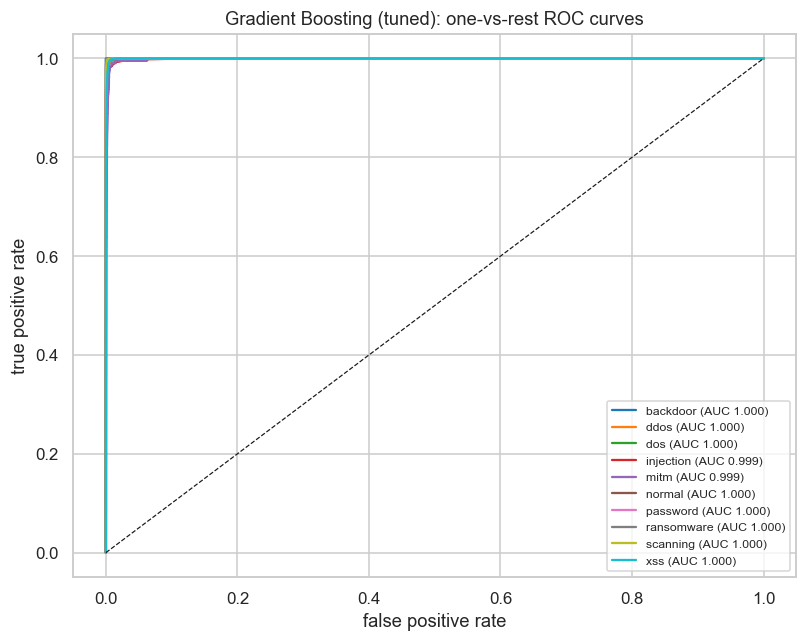

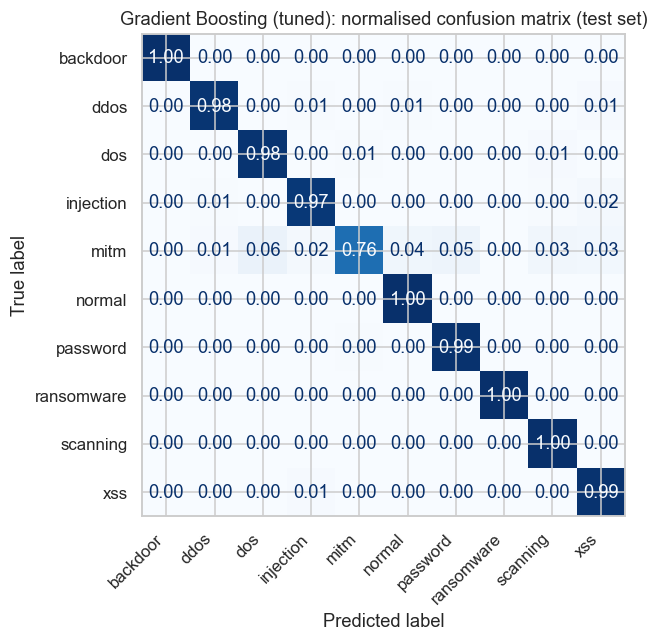

In [24]:
# One-vs-rest ROC curve per class for the final model
Y_bin = label_binarize(y_test, classes=range(len(CLASSES)))
proba = PROBA[f"{best_name} (tuned)"]
fig, ax = plt.subplots(figsize=(7.5, 6))
colors = sns.color_palette("tab10", len(CLASSES))
for k, cls_name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y_bin[:, k], proba[:, k])
    ax.plot(fpr, tpr, color=colors[k], label=f"{cls_name} (AUC {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title(f"{best_name} (tuned): one-vs-rest ROC curves"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "cls_06_roc_final.png"), bbox_inches="tight"); plt.show()
show_cm(f"{best_name} (tuned)")

> **Observation (write in your own words):** Why is this the final model? Weigh test F1, macro F1 (rare classes), CV stability and training time.
>
> _…_

## 9. Stress test: unseen machines
The final model's configuration is retrained on flows from some source machines and tested on flows from **different** machines (`StratifiedGroupKFold` grouped by `src_ip`). Only the classes present in that test fold can be scored.

In [25]:
g_tr, g_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE).split(df, y, groups=df["src_ip"]))
ports_g = df.iloc[g_tr]["dst_port"].value_counts().head(10).index
pre_g = ColumnTransformer([("num", StandardScaler(), num_cols),
                           ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat_cols)])
Xg_tr = pre_g.fit_transform(build_features(df.iloc[g_tr], ports_g))
Xg_te = pre_g.transform(build_features(df.iloc[g_te], ports_g))
from sklearn.base import clone
mg = clone(search.best_estimator_).fit(Xg_tr, y[g_tr])
pg = mg.predict(Xg_te)
present = sorted(set(y[g_te]))
print("classes in the unseen-machine test fold:", [CLASSES[i] for i in present])
print(f"accuracy {accuracy_score(y[g_te], pg):.4f}   weighted F1 {f1_score(y[g_te], pg, average='weighted'):.4f}   "
      f"macro F1 (present classes) {f1_score(y[g_te], pg, average='macro', labels=present):.4f}")

classes in the unseen-machine test fold: ['backdoor', 'ddos', 'dos', 'injection', 'normal', 'password', 'ransomware', 'scanning']
accuracy 0.7361   weighted F1 0.6984   macro F1 (present classes) 0.7315


> **Observation (write in your own words):** How much does performance drop on machines the model has never seen, and what does that say about deploying it on a new network?
>
> _…_

## 10. Save outputs

In [26]:
joblib.dump({"model": final_model, "preprocessor": pre, "top_ports": list(top_ports), "classes": CLASSES,
             "label_encoder": le, "feature_names": FEATURE_NAMES}, os.path.join(OUT_DIR, "classification_best_ton_iot.joblib"))
summary_final = pd.DataFrame(RESULTS).T.sort_values("F1 (w)", ascending=False)
summary_final.to_csv(os.path.join(OUT_DIR, "classification_results_ton_iot.csv"), index_label="Model")
print("saved to", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

saved to ../results
['classification', 'classification_best_ton_iot.joblib', 'classification_cv_ton_iot.csv', 'classification_final_tuning_ton_iot.csv', 'classification_results_ton_iot.csv', 'classification_tuning_ton_iot.csv', 'clustering', 'clustering_assignments_ton_iot.csv', 'clustering_metrics_ton_iot.csv', 'clustering_stability_ton_iot.csv', 'figures', 'regression']
